# SafeBank Assist — Colab run (Group 22)

PCAM ZG516 Applied Generative AI · BANKING77 · `Qwen/Qwen2.5-1.5B-Instruct` (baseline: `gpt2`)

Runs top to bottom on a **free T4** (Runtime → Change runtime type → T4 GPU). This notebook covers environment and reproducibility, the dataset and its preprocessing record, the **E1 baseline**, the tokenizer walkthrough, and an **E7** smoke run. The E2/E3/E6 sweeps build on the objects created here.

Everything written to `artifacts/results/` and `artifacts/figures/` is report evidence.

## 1. Environment

In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv || echo "No GPU: switch the runtime to T4" 

zsh:1: command not found: nvidia-smi
No GPU: switch the runtime to T4


In [ ]:
# Clone the repo (if it is private, use https://<token>@github.com/... or upload a zip).
# Every run deletes and re-clones REPO_DIR at the tip of BRANCH, so a stale runtime
# never runs old code. Restart the runtime afterwards if safebank was already imported.
# Outside Colab the notebook runs against the checkout it lives in.
import os, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
#REPO_URL = "https://github.com/2025paml539-lab/safebank-assist-group22.git"
REPO_URL = "https://github.com/mvishruth-bits/safebank-assist-group22.git"
BRANCH = "main"
if IN_COLAB:
    REPO_DIR = "/content/safebank-assist-group22"
    # Step out first: a re-run is still inside REPO_DIR, and deleting the current
    # directory breaks every shell command after it, including the clone.
    os.chdir("/content")
    !rm -rf {REPO_DIR}
    !git clone -q --branch {BRANCH} {REPO_URL} {REPO_DIR}
else:
    REPO_DIR = subprocess.check_output(["git", "rev-parse", "--show-toplevel"], text=True).strip()
%cd {REPO_DIR}
!git log -1 --format='%h %s'

In [3]:
# Only the packages Colab does not already pin. torch is Colab's preinstalled build;
# its exact version is recorded by device_report() below. Locally, install requirements.txt instead.
if IN_COLAB:
    %pip install -q -r requirements-colab.txt

In [4]:
import sys, json
sys.path.insert(0, "src")

from safebank import config
from safebank.model_loader import device_report

for d in (config.RESULTS_DIR, config.FIGURES_DIR, config.DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)

report = device_report().as_dict()
report.update(seed=config.SEED, model_id=config.MODEL_ID, baseline_model_id=config.BASELINE_MODEL_ID)
(config.RESULTS_DIR / "device_report.json").write_text(json.dumps(report, indent=2))
report

/Users/vishruth/Documents/dev/bits-genai/safebank-assist-group22/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'device': 'cpu',
 'device_name': 'arm',
 'cuda_capability': None,
 'vram_gb': None,
 'torch_version': '2.14.0',
 'transformers_version': '5.19.0',
 'cuda_version': None,
 'dtype': 'float32',
 'seed': 42,
 'model_id': 'Qwen/Qwen2.5-1.5B-Instruct',
 'baseline_model_id': 'gpt2'}

## 2. Dataset: BANKING77

Loads the official PolyAI CSVs with the Hub's canonical label order (the Hub dataset is script-based, which `datasets` ≥ 4 refuses). `load_banking77` runs the mandatory `validate_label_space()` check.

In [5]:
from safebank.data_prep import (
    load_banking77, dataset_label_space, class_distribution,
    build_eval_sample, build_example_bank, preprocessing_record,
)

train, test = load_banking77()
LABELS = dataset_label_space(train)
print(train, test, sep="\n")
print(len(LABELS), "intents, e.g.", LABELS[:5])

Dataset({
    features: ['text', 'label'],
    num_rows: 10003
})
Dataset({
    features: ['text', 'label'],
    num_rows: 3080
})
77 intents, e.g. ['activate_my_card', 'age_limit', 'apple_pay_or_google_pay', 'atm_support', 'automatic_top_up']


In [6]:
eval_rows = build_eval_sample(test, LABELS)            # 5 x 77 = 385, seed 42, TEST split
EXAMPLES = build_example_bank(                         # TRAIN split, never an eval query
    train, LABELS, exclude={r["query"] for r in eval_rows}
)
record = preprocessing_record(train, test, eval_rows)

with open(config.RESULTS_DIR / "eval_sample.jsonl", "w") as f:
    for r in eval_rows:
        f.write(json.dumps(r) + "\n")
(config.RESULTS_DIR / "preprocessing_record.json").write_text(json.dumps(record, indent=2))
(config.RESULTS_DIR / "few_shot_examples.json").write_text(json.dumps(EXAMPLES, indent=2))
record

{'dataset_id': 'PolyAI/banking77',
 'loader': 'official PolyAI CSVs + Hub dataset card (README.md) label order',
 'source_urls': ['https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/train.csv',
  'https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data/test.csv',
  'https://huggingface.co/datasets/PolyAI/banking77/resolve/main/README.md'],
 'n_intents_expected': 77,
 'seed': 42,
 'eval_rows_per_intent': 5,
 'eval_rows_total': 385,
 'eval_source_split': 'test',
 'few_shot_source_split': 'train',
 'preprocessing': ['Strip leading/trailing whitespace from each query (CSV reader output).',
  'No lowercasing, spelling correction or deduplication: queries are kept as the customer wrote them, because noisy phrasing is part of the task.',
  'Evaluation sample drawn from the TEST split only; few-shot examples drawn from the TRAIN split only, excluding any text that also appears in the evaluation sample.',
  'Prompt-time normal

,train,test
count,77.000000,77.0
mean,129.909091,40.0
std,32.942207,0.0
min,35.000000,40.0
25%,112.000000,40.0
50%,127.000000,40.0
75%,159.000000,40.0
max,187.000000,40.0


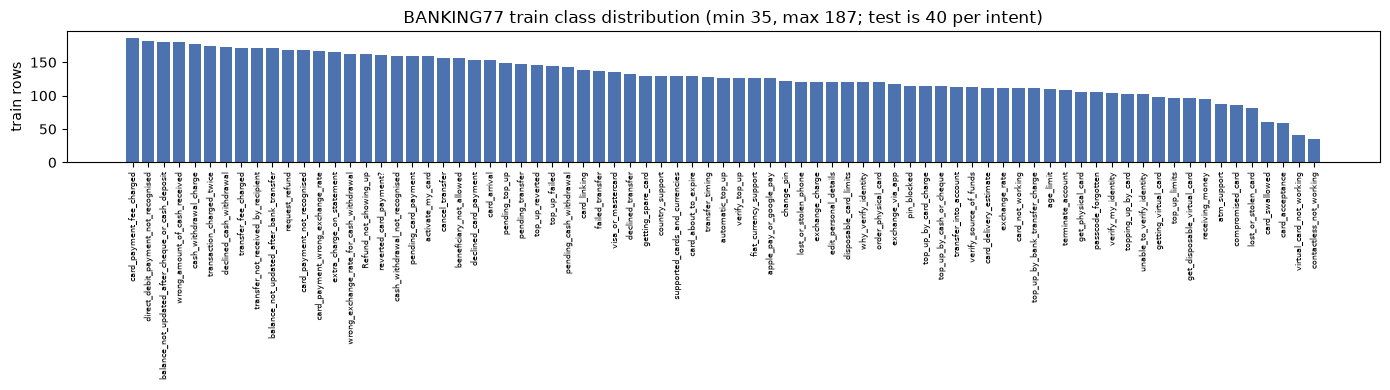

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

dist = pd.DataFrame({
    "train": class_distribution(train, LABELS),
    "test": class_distribution(test, LABELS),
}).sort_values("train", ascending=False)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(len(dist)), dist["train"], color="#4C72B0")
ax.set_xticks(range(len(dist)), dist.index, rotation=90, fontsize=6)
ax.set_ylabel("train rows")
ax.set_title(f"BANKING77 train class distribution (min {dist.train.min()}, max {dist.train.max()}; test is 40 per intent)")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "class_distribution.png", dpi=200)
dist.describe()

In [8]:
# Representative examples table for report section 3
pd.DataFrame(eval_rows).groupby("gold_intent").head(1).head(10)

,query,gold_intent
0,I need to activate my card can you do that now?,activate_my_card
5,How do I go about setting up an account for my...,age_limit
10,Can I use the system Google Pay for top-ups?,apple_pay_or_google_pay
15,Which ATMs accept this card?,atm_support
20,Is there an auto top-up option?,automatic_top_up
25,I made a transfer a few hours ago from a UK ba...,balance_not_updated_after_bank_transfer
30,How can I get the cash deposit to show up on m...,balance_not_updated_after_cheque_or_cash_deposit
35,Can you please help me with this exchange? I ...,beneficiary_not_allowed
40,Can I cancel my transaction?,cancel_transfer
45,"My card's expiring, what happens now?",card_about_to_expire


## 3. E1 — baseline: one simple prompt, GPT-2 vs Qwen

One deliberately plain prompt, no schema, no examples, greedy decoding, the same 5 queries for both models. GPT-2 has no chat template and was not instruction-tuned; that asymmetry is the point of the baseline.

In [9]:
from safebank.generator import DecodeConfig
from safebank.model_loader import load_model_and_tokenizer, HFGenerator, clear_cache

E1_PROMPT = "Customer message: {query}\nWhat does the customer want? Answer in one short sentence.\nAnswer:"
e1_rows = eval_rows[::77][:5]          # 5 different intents, fixed by the seed
greedy = DecodeConfig(max_new_tokens=48)

def run_e1(model_id):
    gen = HFGenerator(*load_model_and_tokenizer(model_id))
    outs = [gen.generate(E1_PROMPT.format(query=r["query"]), greedy) for r in e1_rows]
    return outs, gen.usage_log

gpt2_out, gpt2_usage = run_e1(config.BASELINE_MODEL_ID)
clear_cache()
qwen_out, qwen_usage = run_e1(config.MODEL_ID)

e1 = pd.DataFrame({
    "query": [r["query"] for r in e1_rows],
    "gold_intent": [r["gold_intent"] for r in e1_rows],
    "gpt2": gpt2_out,
    "qwen2.5-1.5b-instruct": qwen_out,
    "gpt2_ms": [u.latency_ms for u in gpt2_usage],
    "qwen_ms": [u.latency_ms for u in qwen_usage],
})
e1.to_csv(config.RESULTS_DIR / "e1_baseline.csv", index=False)
pd.set_option("display.max_colwidth", 120)
e1

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 753.16it/s]
[transformers] The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,query,gold_intent,gpt2,qwen2.5-1.5b-instruct,gpt2_ms,qwen_ms
0,I need to activate my card can you do that now?,activate_my_card,I need to activate my card can you do that now?\nWhat does the customer want? Answer in one short sentence.\nAnswer:...,The customer wants to activate their card immediately.,801.4,596.4
1,I have been charged a fee for paying with card,card_payment_fee_charged,I have been charged a fee for paying with card\nWhat does the customer want? Answer in one short sentence.\nWhat doe...,The customer wants to understand why they were charged a fee for using a card to pay.,351.8,898.4
2,Is it possible to edit my personal details on the app?,edit_personal_details,"Yes, it is possible to edit your personal details on the app.\nWhat does the customer want? Answer in one short sent...",The customer wants to know if they can update their personal information on the app.,332.9,827.8
3,"I tried taking money from the ATM but no money came out, but the transaction is still pending? How is this possible?",pending_cash_withdrawal,I am a customer. I am a customer. I am a customer. I am a customer. I am a customer. I am a customer. I am a custome...,The customer is confused about why their ATM transaction is pending even though no money has come out.,358.5,948.7
4,My top-up was revoked.,top_up_reverted,I'm sorry.\nWhat does the customer want? Answer in one short sentence.\nAnswer: I'm sorry.\nWhat does the customer w...,The customer wants to understand why their top-up was revoked and possibly how to resolve the issue.,319.7,931.3


## 4. Tokenization walkthrough (report §4b)

Real tokenizer output for one query: the text → token ids → the model's vocabulary pieces. Qwen stays loaded from E1.

In [10]:
model, tok = load_model_and_tokenizer(config.MODEL_ID)
q = e1_rows[0]["query"]
ids = tok(q)["input_ids"]
print(q)
print(len(ids), "tokens:", ids)
print([tok.decode([i]) for i in ids])
print("vocab size:", tok.vocab_size, "| hidden size:", model.config.hidden_size,
      "| layers:", model.config.num_hidden_layers, "| heads:", model.config.num_attention_heads,
      "| context:", model.config.max_position_embeddings)

I need to activate my card can you do that now?
12 tokens: [40, 1184, 311, 20276, 847, 3701, 646, 498, 653, 429, 1431, 30]
['I', ' need', ' to', ' activate', ' my', ' card', ' can', ' you', ' do', ' that', ' now', '?']
vocab size: 151643 | hidden size: 1536 | layers: 28 | heads: 12 | context: 32768


## 5. E7 — integrated pipeline smoke run

The real `HFGenerator` replaces `FakeGenerator`; nothing else in the pipeline changes.

In [11]:
from safebank.pipeline import SafeBankPipeline
from safebank.prompts import PromptStrategy

qwen = HFGenerator(model, tok)
pipe = SafeBankPipeline(qwen, LABELS, strategy=PromptStrategy.ZERO_SHOT)

for query in [
    "My new card still hasn't arrived, it's been two weeks",
    "I lost my card on the train this morning",
    "Is there an ATM near 560001?",
]:
    r = pipe.run(query)
    print(query, "\n  ->", json.dumps(r.to_row(), default=str)[:400], "\n  ", r.final_text, "\n")

My new card still hasn't arrived, it's been two weeks 
  -> {"query": "My new card still hasn't arrived, it's been two weeks", "ok": true, "intent": "card_not_working", "confidence": 0.95, "response": "I'm sorry to hear that your new card hasn't arrived yet. We're currently tracking the delivery status of your card. Please check back in a few days to see if it's on its way.", "attempts": 1, "needed_repair": false, "first_failure": null, "tool": null, "tool 
   I'm sorry to hear that your new card hasn't arrived yet. We're currently tracking the delivery status of your card. Please check back in a few days to see if it's on its way.
Information shown is from a simulated system of record, not live banking data. 

I lost my card on the train this morning 
  -> {"query": "I lost my card on the train this morning", "ok": true, "intent": "lost_or_stolen_card", "confidence": 0.95, "response": "I'm sorry to hear that you've lost your card. Please provide your account number and PIN so we can a

## 6. Handover for E2 / E3 / E6

Objects ready for the sweeps: `LABELS`, `eval_rows` (385), `EXAMPLES` (train-split few-shot bank), `qwen` (`HFGenerator`, also has `generate_batch` for speed) and `qwen.usage_log` for token counts (criterion 5).

For the few-shot variant, pass the train-split bank through the pipeline: `SafeBankPipeline(qwen, LABELS, strategy=PromptStrategy.FEW_SHOT, prompt_kwargs={"examples": EXAMPLES})`. Without it the pipeline warns and falls back to the illustrative offline bank, which must not be used for reported E2 numbers.